<a href="https://colab.research.google.com/github/nenatesz/Amazona/blob/master/project_stable_diffusion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install -qq diffusers datasets accelerate peft controlnet-aux wandb open-clip-torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 290.4/290.4 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 42.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 92.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 81.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 53.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 41.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 19.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 43.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 

In [ ]:
import torch
import os
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import pandas as pd
from torchvision import transforms
from diffusers import (ControlNetModel, UNet2DConditionModel, DDPMScheduler, StableDiffusionControlNetPipeline, AutoencoderKL, UniPCMultistepScheduler)
from transformers import CLIPTextModel, CLIPTokenizer
from peft import LoraConfig, get_peft_model
import accelerate
from accelerate import Accelerator
from controlnet_aux import HEDdetector
from accelerate.utils import ProjectConfiguration, set_seed
from diffusers.optimization import get_scheduler
from packaging import version
import math
from tqdm import tqdm
import torch.nn.functional as F

/usr/local/lib/python3.11/dist-packages/controlnet_aux/mediapipe_face/mediapipe_face_common.py:7: UserWarning: The module 'mediapipe' is not installed. The package will have limited functionality. Please install it using the command: pip install 'mediapipe'
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/timm/models/layers/__init__.py:48: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.11/dist-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarning)
/usr/local/lib/python3.11/dist-packages/controlnet_aux/segment_anything/modeling/tiny_vit_sam.py:654: UserWarning: Overwriting tiny_vit_5m_224 in registry with controlnet_aux.segmen

In [ ]:
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True,max_split_size_mb:64"

In [ ]:
device = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [ ]:
node_env = os.getenv("NODEENV", "development")  # default to 'development' if not set

print(f"NODEENV is: {node_env}")

if node_env == "production":
  captions_dir = 'https://drive.google.com/uc?export=download&id=17j_7Bx5f2hkEpJ0IO7w5dkM5Hy9d9Re6'
  image_dir = "./myfolder"
  output_dir = "./output"
else:
  from google.colab import drive
  drive.mount('/content/drive')
  captions_dir = "/content/drive/MyDrive/project - diffusion models/project-poc/bbl_captions_1.csv"
  image_dir = "/content/drive/MyDrive/project - diffusion models/project-poc/poc/bbl"
  output_dir = "/content/drive/MyDrive/project - diffusion models/project-poc/output"
  logging_dir = "/content/drive/MyDrive/project - diffusion models/project-poc/logs"

NODEENV is: development
Mounted at /content/drive


In [ ]:
MODEL_NAME = "runwayml/stable-diffusion-v1-5"
CONTROLNET_NAME = "lllyasviel/sd-controlnet-canny"
# DATA_ROOT = "dataset"
RESOLUTION = 512
BATCH_SIZE = 2
LEARNING_RATE = 1e-5
MAX_TRAIN_STEPS = 1000
LRANK = 16
LORA_ALPHA = 16
GRAD_ACCUM_STEPS = 2
mixed_precision = "fp16"
SEED = 42
EPOCHS = 10
args = {
    "pretrained_model_name": MODEL_NAME,
    "controlnet_model_name": CONTROLNET_NAME,
    "resolution": RESOLUTION,
    "batch_size": BATCH_SIZE,
    "gradient_accumulation_steps": GRAD_ACCUM_STEPS,
    "learning_rate": LEARNING_RATE,
    "max_train_steps": MAX_TRAIN_STEPS,
    "lr_rank": LRANK,
    "lora_alpha": LORA_ALPHA,
    "mixed_precision": mixed_precision,
    # "report_to": "wandb",
    "output_dir": output_dir,
    "logging_dir": logging_dir,
    "seed": SEED,
    "gradient_checkpointing": True,
    "use_8bit_adam": False,
    "dataloader_num_workers": 0,
    "adam_beta1": 0.9,
    "adam_beta2": 0.999,
    "adam_weight_decay": 0.01,
    "adam_epsilon": 1e-8,
    "allow_tf32": False,
    "scale_lr": True,
    "lr_scheduler": "cosine", # examples are linear, contsant, constant_with_warmup
    "lr_warmup_steps": 0,
    "lr_num_cycles": 0.0,
    "lr_power": 1.0,
    "num_train_epochs": EPOCHS,
    "lr_num_cycles": 1,
    "lr_power": 1.0,
    "max_grad_norm": 1.0,
    "set_grads_to_none": False,
  }

In [ ]:
# def load_models():
#   models = {}
#   hed = HEDdetector.from_pretrained('lllyasviel/Annotators')  # Loads the HED model
#   tokenizer = CLIPTokenizer.from_pretrained("openai/clip-vit-large-patch14")
#   models['hed'] = hed
#   models['tokenizer'] = tokenizer
#   return models

In [ ]:
def to_hed():
  hed = HEDdetector.from_pretrained('lllyasviel/Annotators')  # Loads the HED model
  # hed = HEDdetector.from_pretrained('lllyasviel/ControlNet-HED')  # Loads the HED model
  return hed.to(device)

A tokenizer is a tool that converts text into numbers (tokens) that a machine learning model can understand. For example, the word "dog" might become the number 1234, based on the tokenizer’s vocabulary.

In [ ]:
import random
import numpy as np


def tokenize_captions(captions_list, is_train=True):
  tokenizer = CLIPTokenizer.from_pretrained("openai/clip-vit-large-patch14")
  captions = []
  for caption in captions_list:
      # if random.random() < args.proportion_empty_prompts:
      #     captions.append("")
      if isinstance(caption, str):
          captions.append(caption)
      elif isinstance(caption, (list, np.ndarray)):
          # take a random caption if there are multiple
          captions.append(random.choice(caption) if is_train else caption[0])
      else:
          raise ValueError(
              f"Caption column `{captions_list}` should contain either strings or lists of strings."
          )
  inputs = tokenizer(
      captions, max_length=tokenizer.model_max_length, padding="max_length", truncation=True, return_tensors="pt"
  )
  return inputs.input_ids


def get_captions(captions_dir):
  df = pd.read_csv(captions_dir)
  return df

In [ ]:
# df = pd.read_csv(captions_dir)
# df.head(50)

In [ ]:
class ImageToImageDataset(Dataset):
  def __init__(self, df, root, hed, tokenizer, args):
    self.df = df
    self.root = root
    self.hed = hed
    self.args = args
    self.tokenizer = tokenizer
    # Ensure proper checks are applied
    if self.hed is None:
      raise ValueError("Conditioning function not provided")

    if self.tokenizer is None:
      raise ValueError("Tokenizer not provided")

  def __len__(self):
      return len(self.df)

  def __getitem__(self, idx):

    dataset = {}
    pre_file_name = f"pre-{idx + 1}.png"
    post_file_name = f"post-{idx + 1}.png"
    pre_image = Image.open(os.path.join(self.root, "pre-new", pre_file_name)).convert("RGB").resize((512, 512))
    post_image = Image.open(os.path.join(self.root, "post-new", post_file_name)).convert("RGB").resize((512, 512))

    with torch.no_grad():
      conditioning_image = self.hed(pre_image)

    image_transforms = transforms.Compose(
        [
            transforms.Resize(self.args['resolution'], interpolation=transforms.InterpolationMode.BILINEAR),
            transforms.CenterCrop(self.args['resolution']),
            transforms.ToTensor(),
            transforms.Normalize([0.5], [0.5]),
        ]
      )

    # conditioning_image_transforms = transforms.Compose(
    #   [
    #       transforms.Resize(self.args['resolution'], interpolation=transforms.InterpolationMode.BILINEAR),
    #       transforms.CenterCrop(self.args['resolution']),
    #       transforms.ToTensor(),
    #   ]
    # )

    conditioning_image_transforms = transforms.Compose([
      transforms.Resize((512, 512), interpolation=transforms.InterpolationMode.BILINEAR),  # Match args['resolution']
      transforms.CenterCrop(512),
      transforms.ToTensor(),
      transforms.Normalize([0.5], [0.5]),  # Add normalization to match training
      ])


    # pre = image_transforms(pre)
    # post = image_transforms(post)
    # pre_canny = conditioning_image_transforms(pre_canny)

    dataset['pre_op_values'] = image_transforms(pre_image)
    dataset['post_op_values'] = image_transforms(post_image)
    dataset['conditioning_pre_op_values'] = conditioning_image_transforms(conditioning_image)
    dataset['caption'] = self.df.loc[idx, "caption"]
    dataset['input_ids'] = tokenizer([self.df.loc[idx, "caption"]])


    # return {"pre_op": pre, "pre_op_conditioning": conditioning_images, "post_op": post, "caption": self.df.loc[idx, "caption"]}
    return dataset

NameError: name 'Dataset' is not defined

In [ ]:





# def get_train_data():
#   data = {}
#   df = get_captions(captions_dir)
#   hed = to_hed()
#   dataset = ImageToImageDataset(df, image_dir, hed, args)
#   data['post_op_values'] = dataset['post_image']
#   data['conditioning_pre_op_values'] = dataset['conditioning_image']
#   data['input_ids'] = dataset['input_ids']
#   return data

In [ ]:
def collate_fn(dataset):
  post_op_values = torch.stack([example["post_op_values"] for example in dataset])
  post_op_values = post_op_values.to(memory_format=torch.contiguous_format).float()

  conditioning_pre_op_values = torch.stack([example["conditioning_pre_op_values"] for example in dataset])
  conditioning_pre_op_values = conditioning_pre_op_values.to(memory_format=torch.contiguous_format).float()
  # for example in dataset:
  #   print('inpu_IDS ====>', example["input_ids"])
  #   break

  # input_ids = torch.stack([example["input_ids"][0] for example in dataset])
  input_ids = torch.stack([
    torch.tensor(example["input_ids"]['input_ids'][0]) for example in dataset
])
  return {
      "post_op_values": post_op_values,
      "conditioning_pre_op_values": conditioning_pre_op_values,
      "input_ids": input_ids,
  }

In [ ]:
df = get_captions(captions_dir)
hed = to_hed()
tokenizer = CLIPTokenizer.from_pretrained("openai/clip-vit-large-patch14")
dataset = ImageToImageDataset(df, image_dir, hed, tokenizer, args)
# dataset = ImageToImageDataset(df, image_dir, transform)
loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)
import matplotlib.pyplot as plt
import torchvision.transforms.functional as TF

# Get a batch from the DataLoader
batch = next(iter(loader))

# Get the pre-op images
pre_op_images = batch["post_op_values"] # Shape: (batch_size, 3, H, W)
pre_op_images_ = batch["conditioning_pre_op_values"]  # Shape: (batch_size, 3, H, W)
caption = batch['caption']

# Convert and show a few images
def show_images(images, n=None):
    if n is None:
        n = len(images)
    else:
        n = min(n, len(images))  # Avoid IndexError

    plt.figure(figsize=(15, 5))
    for i in range(n):

      img = images[i]
      img = TF.to_pil_image(img * 0.5 + 0.5)  # De-normalize
      plt.subplot(1, n, i + 1)
      plt.imshow(img)
      plt.axis("off")
    plt.show()

# Automatically show all images in the batch (or set n=2, 3, etc.)
show_images(pre_op_images)
show_images(pre_op_images_)
print(caption)

In [ ]:
def log_validation(vae, text_encoder, tokenizer, unet, controlnet, args, accelerator, weight_dtype, step):
    pipeline = StableDiffusionControlNetPipeline.from_pretrained(
        args["pretrained_model_name"], vae=vae, text_encoder=text_encoder, unet=unet, controlnet=controlnet,
        torch_dtype=weight_dtype
    ).to(accelerator.device)
    validation_image = Image.open("path/to/validation_pre_op.jpg").convert("RGB")
    validation_image = transforms.Compose([
        transforms.Resize((args["resolution"], args["resolution"])),
        transforms.ToTensor(),
        transforms.Normalize([0.5], [0.5])
    ])(validation_image)
    image = pipeline(
        args["validation_prompt"], image=validation_image, num_inference_steps=20, guidance_scale=7.5
    ).images[0]
    image.save(os.path.join(args["output_dir"], f"validation_{step}.png"))
    return image

In [ ]:
def main(args):
  # logging_dir = os.path.join(args["output_dir"], args["logging_dir"])
  accelerator_project_config = ProjectConfiguration(project_dir=output_dir)
  accelerator = Accelerator(
      gradient_accumulation_steps=args['gradient_accumulation_steps'],
      mixed_precision=args["mixed_precision"],
      # log_with=args.report_to,
      project_config=accelerator_project_config,
    )
  if torch.backends.mps.is_available():
    accelerator.native_amp = False

  if args["seed"] is not None:
    set_seed(args["seed"])

  if accelerator.is_main_process:
    if args["output_dir"] is not None:
        os.makedirs(args["output_dir"], exist_ok=True)

  # text_encoder_cls = import_model_class_from_model_name_or_path(args.pretrained_model_name_or_path, args.revision)
  # text_encoder = text_encoder_cls.from_pretrained(
  #     args.pretrained_model_name_or_path, subfolder="text_encoder", revision=args.revision, variant=args.variant
  # )
  # text_encoder = CLIPTextModel.from_pretrained("openai/clip-vit-large-patch14", torch_dtype=torch.float16).to(device)
  text_encoder = CLIPTextModel.from_pretrained(args["pretrained_model_name"], subfolder="text_encoder", torch_dtype=torch.float16).to(device)
  noise_scheduler = DDPMScheduler.from_pretrained(args["pretrained_model_name"], subfolder="scheduler")
  vae = AutoencoderKL.from_pretrained(
      args["pretrained_model_name"], subfolder="vae"
  )
  unet = UNet2DConditionModel.from_pretrained(
      args["pretrained_model_name"], subfolder="unet"
  )
  if args["controlnet_model_name"]:
    print("----")
    controlnet = ControlNetModel.from_pretrained(args["controlnet_model_name"])
  else:
    controlnet = ControlNetModel.from_unet(unet)


  def unwrap_model(model):
    model = accelerator.unwrap_model(model)
    # model = model._orig_mod if is_compiled_module(model) else model
    return model

  if version.parse(accelerate.__version__) >= version.parse("0.16.0"):

    def save_model_hook(models, weights, output_dir):
      if accelerator.is_main_process:
        i = len(weights) - 1
        while len(weights) > 0:
          weights.pop()
          model = models[i]
          sub_dir = "controlnet"
          model.save_pretrained(os.path.join(output_dir, sub_dir))
          i -= 1

    def load_model_hook(models, input_dir):
      while len(models) > 0:
        model = models.pop()
        load_model = ControlNetModel.from_pretrained(input_dir, subfolder="controlnet")
        model.register_to_config(**load_model.config)
        model.load_state_dict(load_model.state_dict())
        del load_model

    accelerator.register_save_state_pre_hook(save_model_hook)
    accelerator.register_load_state_pre_hook(load_model_hook)
  vae.requires_grad_(False)
  unet.requires_grad_(False)
  text_encoder.requires_grad_(False)
  controlnet.train()

  if args["gradient_checkpointing"]:
    controlnet.enable_gradient_checkpointing()

  # Check that all trainable models are in full precision
  low_precision_error_string = (
      " Please make sure to always have all model weights in full float32 precision when starting training - even if"
      " doing mixed precision training, copy of the weights should still be float32."
  )

  if unwrap_model(controlnet).dtype != torch.float32:
    raise ValueError(f"Controlnet loaded as datatype {unwrap_model(controlnet).dtype}. {low_precision_error_string}")

  if args["allow_tf32"]:
    torch.backends.cuda.matmul.allow_tf32 = True

  if args["scale_lr"]:
    args["learning_rate"] = (
        args["learning_rate"] * args["gradient_accumulation_steps"] * args["batch_size"] * accelerator.num_processes
    )

  # Use 8-bit Adam for lower memory usage or to fine-tune the model in 16GB GPUs
  if args["use_8bit_adam"]:
      try:
          import bitsandbytes as bnb
      except ImportError:
          raise ImportError(
              "To use 8-bit Adam, please install the bitsandbytes library: `pip install bitsandbytes`."
          )

      optimizer_class = bnb.optim.AdamW8bit
  else:
    optimizer_class = torch.optim.AdamW


  # Optimizer creation
  params_to_optimize = controlnet.parameters()
  optimizer = optimizer_class(
      params_to_optimize,
      lr=args["learning_rate"],
      betas=(args["adam_beta1"], args["adam_beta2"]),
      weight_decay=args["adam_weight_decay"],
      eps=args["adam_epsilon"],
  )

  train_dataset = ImageToImageDataset(df, image_dir, hed, tokenizer, args)
  # dataset = ImageToImageDataset(df, image_dir, transform)
  train_dataloader = torch.utils.data.DataLoader(
    train_dataset,
    shuffle=True,
    collate_fn=collate_fn,
    batch_size=args["batch_size"],
    num_workers=args["dataloader_num_workers"],
  )
  # loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)


  # Scheduler and math around the number of training steps.
  # Check the PR https://github.com/huggingface/diffusers/pull/8312 for detailed explanation.
  num_warmup_steps_for_scheduler = args["lr_warmup_steps"] * accelerator.num_processes
  if args["max_train_steps"] is None:
      len_train_dataloader_after_sharding = math.ceil(len(train_dataloader) / accelerator.num_processes)
      num_update_steps_per_epoch = math.ceil(len_train_dataloader_after_sharding / args["gradient_accumulation_steps"])
      num_training_steps_for_scheduler = (
          args["num_train_epochs"] * num_update_steps_per_epoch * accelerator.num_processes
      )
  else:
      num_training_steps_for_scheduler = args["max_train_steps"] * accelerator.num_processes

  lr_scheduler = get_scheduler(
      args["lr_scheduler"],
      optimizer=optimizer,
      num_warmup_steps=num_warmup_steps_for_scheduler,
      num_training_steps=num_training_steps_for_scheduler,
      num_cycles=args["lr_num_cycles"],
      power=args["lr_power"],
  )

  # Prepare everything with our `accelerator`.
  controlnet, optimizer, train_dataloader, lr_scheduler = accelerator.prepare(
      controlnet, optimizer, train_dataloader, lr_scheduler
  )

  weight_dtype = torch.float32
  if accelerator.mixed_precision == "fp16":
      weight_dtype = torch.float16
  elif accelerator.mixed_precision == "bf16":
      weight_dtype = torch.bfloat16
  vae.to(accelerator.device, dtype=weight_dtype)
  unet.to(accelerator.device, dtype=weight_dtype)
  text_encoder.to(accelerator.device, dtype=weight_dtype)

  # We need to recalculate our total training steps as the size of the training dataloader may have changed.
  num_update_steps_per_epoch = math.ceil(len(train_dataloader) / args["gradient_accumulation_steps"])
  if args["max_train_steps"] is None:
    args["max_train_steps"] = args["num_train_epochs"] * num_update_steps_per_epoch
    if num_training_steps_for_scheduler != args["max_train_steps"] * accelerator.num_processes:
      print(
          f"The length of the 'train_dataloader' after 'accelerator.prepare' ({len(train_dataloader)}) does not match "
          f"the expected length ({len_train_dataloader_after_sharding}) when the learning rate scheduler was created. "
          f"This inconsistency may result in the learning rate scheduler not functioning properly."
      )


  # Afterwards we recalculate our number of training epochs
  args["num_train_epochs"] = math.ceil(args["max_train_steps"] / num_update_steps_per_epoch)
  print(f"Total number of training epochs: {args['num_train_epochs']}")

  global_step = 0
  first_epoch = 0
  initial_global_step = 0
  progress_bar = tqdm(range(0, args["max_train_steps"]), initial=initial_global_step, desc="Steps", disable=not accelerator.is_local_main_process)
  for epoch in range(first_epoch, args["num_train_epochs"]):
    print(epoch, 'Training Started!')
    for step, batch in enumerate(train_dataloader):
      with accelerator.accumulate(controlnet):
        latents = vae.encode(batch["post_op_values"].to(dtype=weight_dtype)).latent_dist.sample()
        latents = latents * vae.config.scaling_factor
        noise = torch.randn_like(latents)
        bsz = latents.shape[0]
        timesteps = torch.randint(0, noise_scheduler.config.num_train_timesteps, (bsz,), device=latents.device)
        timesteps = timesteps.long()
        noisy_latents = noise_scheduler.add_noise(latents.float(), noise.float(), timesteps).to(dtype=weight_dtype)
        encoder_hidden_states = text_encoder(batch["input_ids"], return_dict=False)[0]
        controlnet_image = batch["conditioning_pre_op_values"].to(dtype=weight_dtype)
        down_block_res_samples, mid_block_res_sample = controlnet(
            noisy_latents, timesteps, encoder_hidden_states=encoder_hidden_states, controlnet_cond=controlnet_image, return_dict=False
        )
        model_pred = unet(
            noisy_latents, timesteps, encoder_hidden_states=encoder_hidden_states,
            down_block_additional_residuals=[sample.to(dtype=weight_dtype) for sample in down_block_res_samples],
            mid_block_additional_residual=mid_block_res_sample.to(dtype=weight_dtype), return_dict=False
        )[0]
        if noise_scheduler.config.prediction_type == "epsilon":
            target = noise
        elif noise_scheduler.config.prediction_type == "v_prediction":
            target = noise_scheduler.get_velocity(latents, noise, timesteps)
        else:
            raise ValueError(f"Unknown prediction type {noise_scheduler.config.prediction_type}")
        loss = F.mse_loss(model_pred.float(), target.float(), reduction="mean")
        accelerator.backward(loss)
        if accelerator.sync_gradients:
          params_to_clip = controlnet.parameters()
          accelerator.clip_grad_norm_(params_to_clip, args["max_grad_norm"])
          progress_bar.update(1)
          global_step += 1
        optimizer.step()
        lr_scheduler.step()
        optimizer.zero_grad(set_to_none=args["set_grads_to_none"])



      # if accelerator.sync_gradients:
    # if accelerator.is_main_process:
    #   if global_step % args.checkpointing_steps == 0:
    #     if args.checkpoints_total_limit is not None:
    #       checkpoints = os.listdir(args.output_dir)
    #       checkpoints = [d for d in checkpoints if d.startswith("checkpoint")]
    #       checkpoints = sorted(checkpoints, key=lambda x: int(x.split("-")[1]))
    #       if len(checkpoints) >= args.checkpoints_total_limit:
    #         num_to_remove = len(checkpoints) - args.checkpoints_total_limit + 1
    #         for removing_checkpoint in checkpoints[0:num_to_remove]:
    #           removing_checkpoint = os.path.join(args.output_dir, removing_checkpoint)
    #           shutil.rmtree(removing_checkpoint)
    #       save_path = os.path.join(args.output_dir, f"checkpoint-{global_step}")
    #       accelerator.save_state(save_path)
    #     if args.validation_prompt is not None and global_step % args.validation_steps == 0:
    #       image_logs = log_validation(vae, text_encoder, tokenizer, unet, controlnet, args, accelerator, weight_dtype, global_step)



  accelerator.wait_for_everyone()
  if accelerator.is_main_process:
    controlnet = unwrap_model(controlnet)
    print("Saving Model!")
    controlnet.save_pretrained(args["output_dir"])
    # if args.validation_prompt is not None:
    #     image_logs = log_validation(
    #         vae=vae, text_encoder=text_encoder, tokenizer=tokenizer, unet=unet, controlnet=None,
    #         args=args, accelerator=accelerator, weight_dtype=weight_dtype, step=global_step, is_final_validation=True
    #     )
  accelerator.end_training()






In [ ]:
if __name__ == "__main__":
    # args = parse_args()
    main(args)

NameError: name 'args' is not defined

In [ ]:
# Install dependencies
# !pip install diffusers transformers torch accelerate opencv-python controlnet-aux

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Import libraries
import torch
from diffusers import StableDiffusionControlNetPipeline, ControlNetModel, UniPCMultistepScheduler
from torchvision import transforms
from PIL import Image
import cv2
from controlnet_aux import HEDdetector

# Define device
device = "cuda" if torch.cuda.is_available() else "cpu"

# Load the HED detector
def to_hed():
    hed = HEDdetector.from_pretrained('lllyasviel/Annotators').to(device)
    return hed

hed = to_hed()

# Define preprocessing transforms (matching training)
conditioning_image_transforms = transforms.Compose([
    transforms.Resize((512, 512), interpolation=transforms.InterpolationMode.BILINEAR),  # Match args['resolution']
    transforms.CenterCrop(512),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5]),  # Add normalization to match training
])

# # Load and preprocess the pre-op image
# from google.colab import files
# uploaded = files.upload()
# pre_op_image_path = list(uploaded.keys())[0]
pre_op_image = Image.open(f"{image_dir}/test-images/1.png").convert("RGB")

# Apply HED detector
with torch.no_grad():
    conditioning_image = hed(pre_op_image)  # Returns a PIL Image (RGB edge map)

# Apply transforms and add batch dimension
conditioning_image = conditioning_image_transforms(conditioning_image).unsqueeze(0).to(device, dtype=torch.float16)

# # Load the saved ControlNet model
# controlnet_path = "/content/drive/MyDrive/output/controlnet"
controlnet = ControlNetModel.from_pretrained(args['output_dir'], torch_dtype=torch.float16)
# controlnet = ControlNetModel.from_pretrained(controlnet_path, torch_dtype=torch.float16)

# Load the Stable Diffusion pipeline
pretrained_model_name = "runwayml/stable-diffusion-v1-5"
pipeline = StableDiffusionControlNetPipeline.from_pretrained(
    pretrained_model_name,
    controlnet=controlnet,
    torch_dtype=torch.float16,
    safety_checker=None
).to(device)

# Configure the scheduler
pipeline.scheduler = UniPCMultistepScheduler.from_config(pipeline.scheduler.config)

# Define prompt
prompt = "moderate buttock increase"
# negative_prompt = "blurry, low quality, distorted, unrealistic"

# Generate the image
image = pipeline(
    prompt=prompt,
    image=conditioning_image,
    # negative_prompt=negative_prompt,
    num_inference_steps=20,
    guidance_scale=7.5,
    controlnet_conditioning_scale=1.0,
).images[0]

# Save and display
# output_path = f"{args['output_dir']}/generated_images/generated_post_op.png"
# if output_path is not None:
#   os.makedirs(output_path, exist_ok=True)
# image.save(output_path)
# print(f"Image saved to {output_path}")
image.show()

In [ ]:
# Save and display
# output_path = f"{args['output_dir']}/generated_images/generated_post_op.png"
# if not os.path.exists(output_dir):
#   os.makedirs(output_dir, exist_ok=True)

# if output_path is not None:
#   os.makedirs(output_path, exist_ok=True)
# image.save(output_path)
# print(f"Image saved to {output_path}")

import random
value = random.random()
digits = str(value).replace("0.", "")[:5]  # Get first 5 digits after "0."

print(digits)
# This is the full output file path
output_path = f"{args['output_dir']}/generated_images/{prompt}_{digits}.png"

# Extract just the directory part
output_dir = os.path.dirname(output_path)

# Create the directory if it doesn't exist
os.makedirs(output_dir, exist_ok=True)

# Save the image
image.save(output_path)


In [ ]:
import random
print(args['output_dir'])
value = random.random()
digits = str(value).replace("0.", "")[:5]  # Get first 5 digits after "0."

print(digits)

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.controlnet.pipeline_controlnet.StableDiffusionControlNetPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

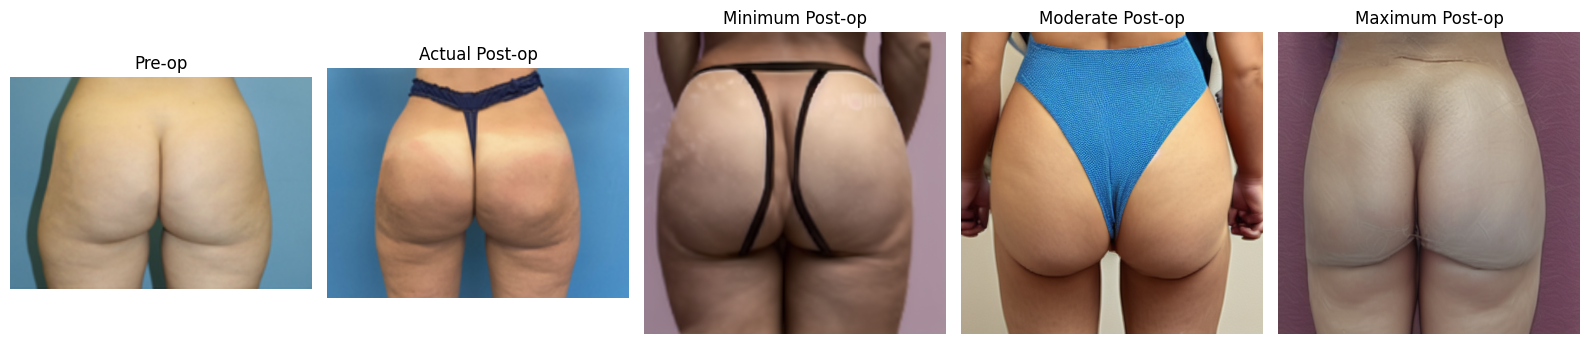

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

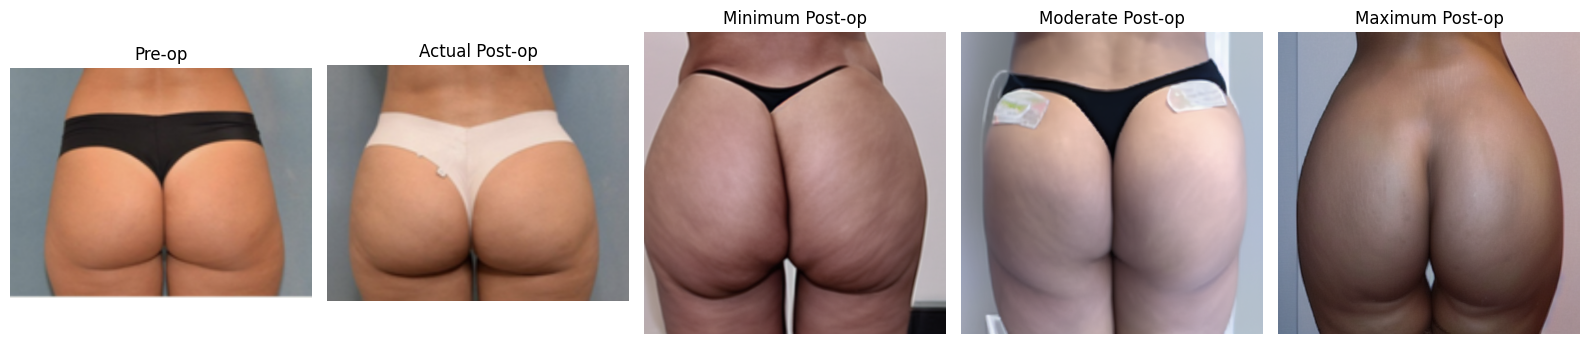

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

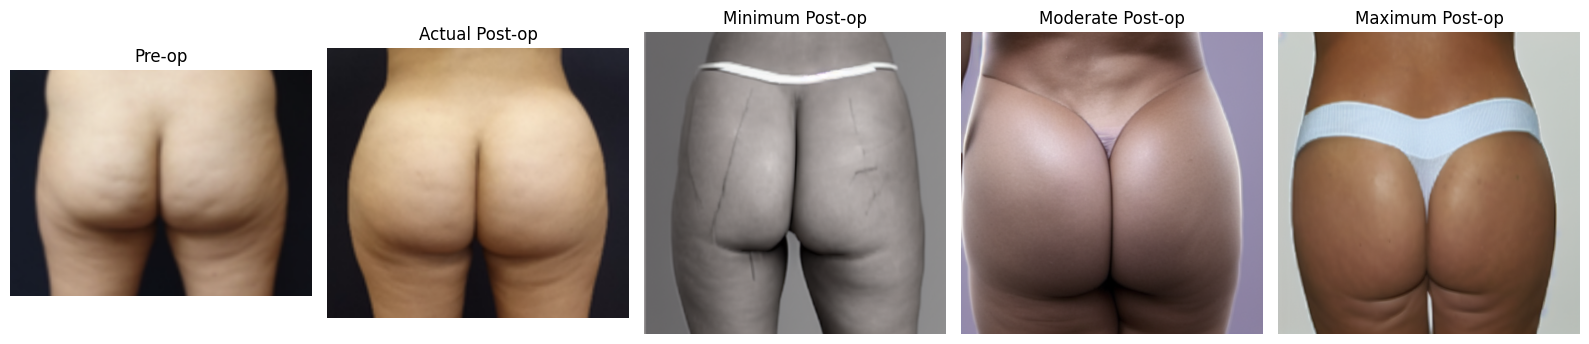

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

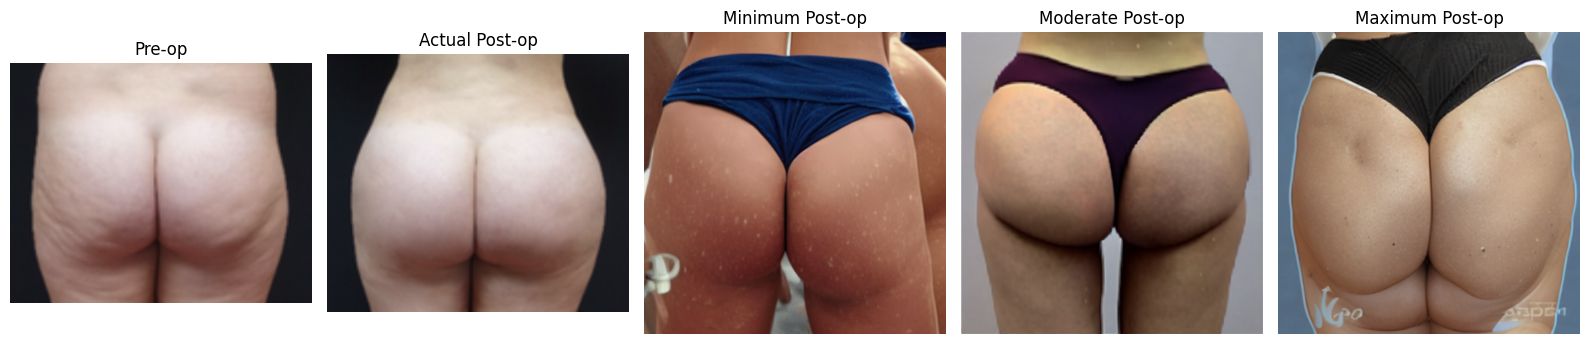

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

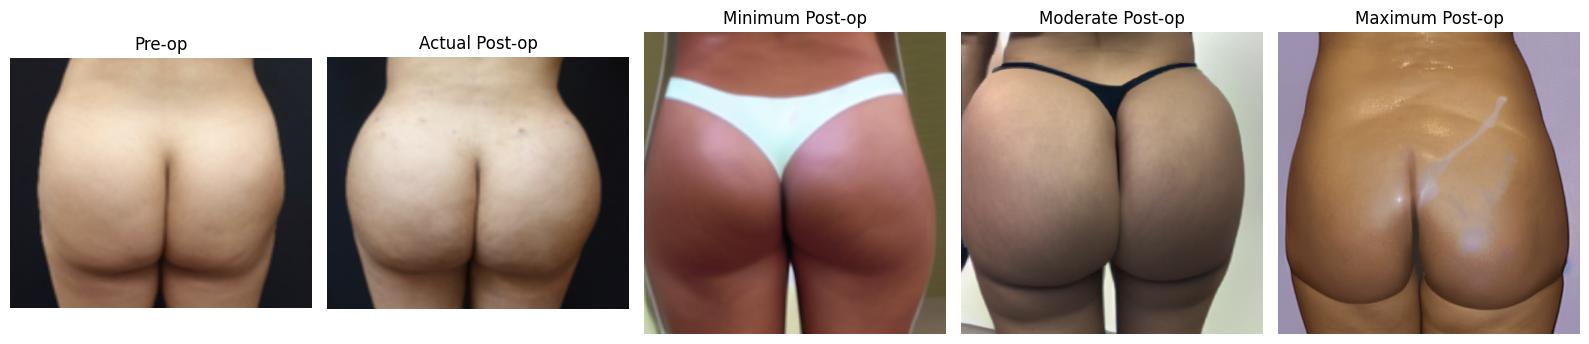

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

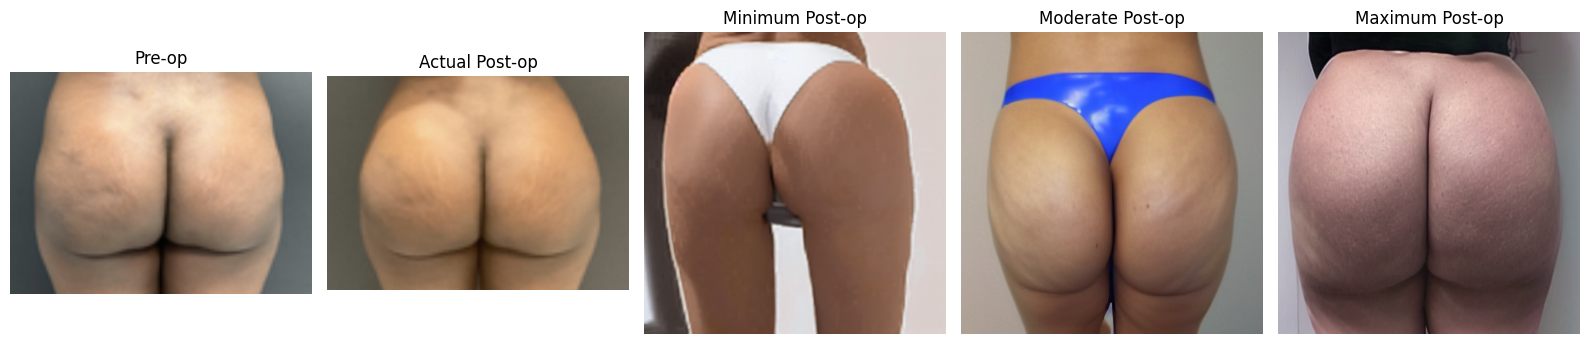

In [ ]:
import os
import matplotlib.pyplot as plt
import torch
from diffusers import StableDiffusionControlNetPipeline, ControlNetModel, UniPCMultistepScheduler
from torchvision import transforms
from PIL import Image
from controlnet_aux import HEDdetector

# Define your variation prompts
variation_prompts = {
    "minimum": "slight buttock enhancement",
    "moderate": "moderate buttock increase",
    "maximum": "significant buttock augmentation"
}

# Directory containing pre-op test images
pre_image_dir = "/content/drive/MyDrive/project - diffusion models/project-poc/poc/bbl/test-images/pre"
post_image_dir = "/content/drive/MyDrive/project - diffusion models/project-poc/poc/bbl/test-images/post"
output_dir = f"{args['output_dir']}/generated_variations"
os.makedirs(output_dir, exist_ok=True)

# Get list of image paths
pre_image_paths = [os.path.join(pre_image_dir, fname) for fname in sorted(os.listdir(pre_image_dir)) if fname.endswith((".png", ".jpg"))]
post_image_paths = [os.path.join(post_image_dir, fname) for fname in sorted(os.listdir(post_image_dir)) if fname.endswith((".png", ".jpg"))]


# Load the HED detector
def to_hed():
    hed = HEDdetector.from_pretrained('lllyasviel/Annotators').to(device)
    return hed

hed = to_hed()

# Define preprocessing transforms (matching training)
conditioning_image_transforms = transforms.Compose([
    transforms.Resize((512, 512), interpolation=transforms.InterpolationMode.BILINEAR),  # Match args['resolution']
    transforms.CenterCrop(512),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5]),  # Add normalization to match training
])

controlnet = ControlNetModel.from_pretrained(args['output_dir'], torch_dtype=torch.float16)
pretrained_model_name = "runwayml/stable-diffusion-v1-5"
pipeline = StableDiffusionControlNetPipeline.from_pretrained(
    pretrained_model_name,
    controlnet=controlnet,
    torch_dtype=torch.float16,
    safety_checker=None
).to(device)

# Configure the scheduler
pipeline.scheduler = UniPCMultistepScheduler.from_config(pipeline.scheduler.config)

# Helper: Generate variations
def generate_variations(pre_op_image):
    with torch.no_grad():
        conditioning = hed(pre_op_image)

    conditioning_tensor = conditioning_image_transforms(conditioning).unsqueeze(0).to(device, dtype=torch.float16)

    images = {}
    for level, prompt in variation_prompts.items():
        result = pipeline(
            prompt=prompt,
            image=conditioning_tensor,
            num_inference_steps=20,
            guidance_scale=7.5,
            controlnet_conditioning_scale=1.0,
        ).images[0]
        images[level] = result
    return images

# Process and visualize

for i, pre_img_path in enumerate(pre_image_paths):
  # Correctly access the corresponding post-op image path
  post_img_path = post_image_paths[i]

  pre_op = Image.open(pre_img_path).convert("RGB")
  post_op = Image.open(post_img_path).convert("RGB")
  variations = generate_variations(pre_op)

  # Plot original + 3 variations
  fig, axs = plt.subplots(1, 5, figsize=(16, 5))
  axs[0].imshow(pre_op)
  axs[0].set_title("Pre-op")
  axs[0].axis("off")

  axs[1].imshow(post_op)
  axs[1].set_title("Actual Post-op")
  axs[1].axis("off")

  for j, level in enumerate(["minimum", "moderate", "maximum"]):
      axs[j+2].imshow(variations[level]) # Adjusted index to j+2
      axs[j+2].set_title(f"{level.capitalize()} Post-op") # Adjusted index to j+2
      axs[j+2].axis("off") # Adjusted index to j+2

      # Optionally save
      save_path = os.path.join(output_dir, f"{i + 1}_{level}.png")
      variations[level].save(save_path)

  plt.tight_layout()
  plt.show()

In [ ]:
pre_image_paths = sorted(pre_image_paths, key=lambda x: x.split('-')[-1])
print(post_image_paths[1])

IndexError: string index out of range

In [ ]:
post_image_paths

'c'